# 02 - Kalman filter with an intercept (2D state)

In notebook 01 the model was $y_t = \beta_t x_t + \epsilon_t$. Real pairs almost never work that way, because the two prices don't line up through zero. The honest model has an intercept:

$$y_t = \alpha_t + \beta_t x_t + \epsilon_t$$

If I leave $\alpha$ out, the filter has to squeeze the intercept into $\beta$, and the hedge ratio comes out wrong.

**Intuition:** I now have two hidden numbers instead of one. The filter keeps a belief about both, plus a $2 \times 2$ covariance matrix $P$ that also records how the two uncertainties are linked (if I'm too high on one, am I probably too low on the other?).

**Math:** the state is $\theta_t = [\beta_t, \alpha_t]^T$ and the observation row is $h_t = [x_t, 1]$, so

$$y_t = h_t \theta_t + \epsilon_t, \qquad \theta_t = \theta_{t-1} + w_t, \quad w_t \sim N(0, Q), \quad Q = \mathrm{diag}(q_\beta, q_\alpha)$$

Each day:

- **Predict:** $\theta_{t|t-1} = \theta_{t-1}$ and $P_{t|t-1} = P_{t-1} + Q$
- **Innovation:** $e_t = y_t - h_t \theta_{t|t-1}$
- **Innovation variance:** $S_t = h_t P_{t|t-1} h_t^T + R$ (a single number)
- **Gain:** $K_t = P_{t|t-1} h_t^T / S_t$ (a vector, one weight per state)
- **Update:** $\theta_t = \theta_{t|t-1} + K_t e_t$ and $P_t = (I - K_t h_t) P_{t|t-1}$

These are the same steps as notebook 01 with the scalars replaced by vectors and matrices. They are also the same covariance, gain and update steps I used in the error-state EKF for VIO.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
num_days = 500
true_beta_start = 1.5
true_alpha_start = 5.0
true_beta_process_std = 0.01     # how fast the true beta drifts per day
true_alpha_process_std = 0.05    # how fast the true intercept drifts per day
true_measurement_std = 1.0

# what the filter assumes (it never sees the true values)
process_noise_Q = np.diag([0.01 ** 2, 0.05 ** 2])
measurement_noise_R = 1.0 ** 2
initial_state_guess = np.array([0.0, 0.0])                # [beta, alpha], wrong on purpose
initial_state_covariance = np.diag([1.0, 100.0])          # alpha is far from 0, so be less sure about it

random_generator = np.random.default_rng(seed=42)

## Simulate the data

Same idea as before, except the true intercept now drifts too.

In [3]:
x_prices = 100 + np.cumsum(random_generator.normal(0, 1.0, size=num_days))

true_beta = true_beta_start + np.cumsum(random_generator.normal(0, true_beta_process_std, size=num_days))
true_alpha = true_alpha_start + np.cumsum(random_generator.normal(0, true_alpha_process_std, size=num_days))

measurement_noise = random_generator.normal(0, true_measurement_std, size=num_days)
y_prices = true_alpha + true_beta * x_prices + measurement_noise

## Baseline: the notebook 01 filter (no intercept)

I run the old filter on this data to see what leaving out the intercept does.

In [4]:
beta_no_intercept = np.zeros(num_days)
innovations_no_intercept = np.zeros(num_days)

beta_previous = 0.0
P_previous = 1.0

for day in range(num_days):
    x_today = x_prices[day]
    y_today = y_prices[day]

    beta_predicted = beta_previous
    P_predicted = P_previous + 0.01 ** 2

    innovation = y_today - x_today * beta_predicted
    innovation_variance = x_today ** 2 * P_predicted + measurement_noise_R
    kalman_gain = P_predicted * x_today / innovation_variance

    beta_updated = beta_predicted + kalman_gain * innovation
    P_updated = (1 - kalman_gain * x_today) * P_predicted

    beta_no_intercept[day] = beta_updated
    innovations_no_intercept[day] = innovation
    beta_previous = beta_updated
    P_previous = P_updated

## The 2D filter

The loop has the same shape as before. The difference is that the state is a vector of length 2, the covariance is a $2 \times 2$ matrix, and the observation row changes every day because it contains $x_t$.

In [5]:
state_estimates = np.zeros((num_days, 2))                  # columns: [beta, alpha]
state_covariances = np.zeros((num_days, 2, 2))
innovations_2d = np.zeros(num_days)
innovation_variances = np.zeros(num_days)

state_previous = initial_state_guess
covariance_previous = initial_state_covariance
identity_matrix = np.eye(2)

for day in range(num_days):
    # observation row: y = beta * x + alpha * 1
    observation_row = np.array([x_prices[day], 1.0])
    y_today = y_prices[day]

    # predict: both parameters follow random walks, so yesterday's values are the best guess,
    # and the uncertainty grows by Q
    state_predicted = state_previous
    covariance_predicted = covariance_previous + process_noise_Q

    # how wrong was the prediction of y
    innovation = y_today - observation_row @ state_predicted

    # expected size of that surprise: uncertainty in (beta, alpha) seen through the observation row, plus noise
    innovation_variance = observation_row @ covariance_predicted @ observation_row + measurement_noise_R

    # gain vector: how much of the surprise to assign to beta and how much to alpha
    kalman_gain = covariance_predicted @ observation_row / innovation_variance

    state_updated = state_predicted + kalman_gain * innovation
    covariance_updated = (identity_matrix - np.outer(kalman_gain, observation_row)) @ covariance_predicted

    state_estimates[day] = state_updated
    state_covariances[day] = covariance_updated
    innovations_2d[day] = innovation
    innovation_variances[day] = innovation_variance

    state_previous = state_updated
    covariance_previous = covariance_updated

## Results

I skip the first 50 days so the deliberately wrong starting guess doesn't dominate the errors.

**My prediction:** Without the intercept, the filter has to explain the missing level through beta, so the beta estimate will probably sit away from the truth. With the intercept, beta should improve. Alpha will likely be harder to recover than beta. In this run x stays between about 84 and 105, so a change in alpha can be imitated by a small change in beta.

In [6]:
beta_error_no_intercept = np.mean(np.abs(beta_no_intercept[50:] - true_beta[50:]))
beta_error_with_intercept = np.mean(np.abs(state_estimates[50:, 0] - true_beta[50:]))
alpha_error_with_intercept = np.mean(np.abs(state_estimates[50:, 1] - true_alpha[50:]))

print("mean abs error in beta, no intercept:  ", round(beta_error_no_intercept, 4))
print("mean abs error in beta, with intercept:", round(beta_error_with_intercept, 4))
print("mean abs error in alpha, with intercept:", round(alpha_error_with_intercept, 4))
print()

# the innovation is the one-step-ahead prediction error of y, and it will become the trading spread
print("mean abs innovation, no intercept:  ", round(np.mean(np.abs(innovations_no_intercept[50:])), 4))
print("mean abs innovation, with intercept:", round(np.mean(np.abs(innovations_2d[50:])), 4))

mean abs error in beta, no intercept:   0.0511
mean abs error in beta, with intercept: 0.0177
mean abs error in alpha, with intercept: 1.6829

mean abs innovation, no intercept:   1.238
mean abs innovation, with intercept: 1.2377


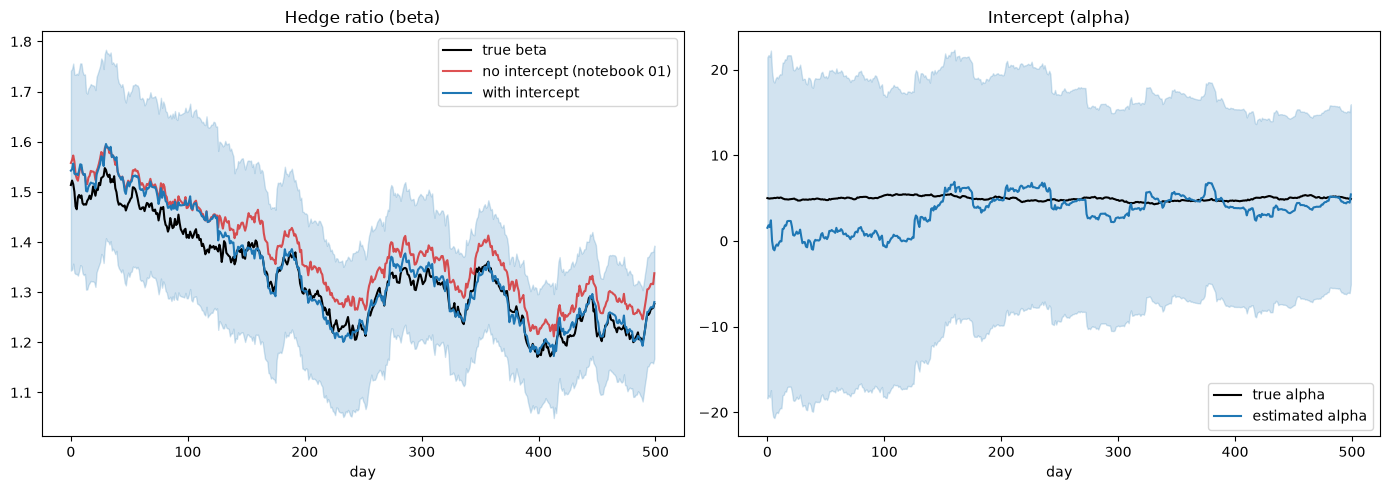

In [7]:
beta_std = np.sqrt(state_covariances[:, 0, 0])
alpha_std = np.sqrt(state_covariances[:, 1, 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(true_beta, color="black", label="true beta")
axes[0].plot(beta_no_intercept, color="tab:red", alpha=0.8, label="no intercept (notebook 01)")
axes[0].plot(state_estimates[:, 0], color="tab:blue", label="with intercept")
axes[0].fill_between(range(num_days),
                     state_estimates[:, 0] - 2 * beta_std,
                     state_estimates[:, 0] + 2 * beta_std,
                     color="tab:blue", alpha=0.2)
axes[0].set_title("Hedge ratio (beta)")
axes[0].set_xlabel("day")
axes[0].legend()

axes[1].plot(true_alpha, color="black", label="true alpha")
axes[1].plot(state_estimates[:, 1], color="tab:blue", label="estimated alpha")
axes[1].fill_between(range(num_days),
                     state_estimates[:, 1] - 2 * alpha_std,
                     state_estimates[:, 1] + 2 * alpha_std,
                     color="tab:blue", alpha=0.2)
axes[1].set_title("Intercept (alpha)")
axes[1].set_xlabel("day")
axes[1].legend()

plt.tight_layout()
plt.show()

The intercept cut the mean absolute error in beta from 0.051 to 0.018, about three times lower. The no-intercept estimate runs above the true beta for most of the run, because the missing level gets absorbed into it. Alpha was recovered poorly, with a mean absolute error of 1.68 on a true value near 5, and its band stays at about plus or minus 10 even on the last day.

One result was unexpected. The one-step prediction errors are almost the same with and without the intercept (1.238 versus 1.238). A beta that wanders can imitate an intercept, so the spread alone would not reveal the problem. The intercept matters for getting the hedge ratio itself right.

## What does the off-diagonal of P say?

$P$ is a $2 \times 2$ matrix. Its diagonal holds the variance of each estimate. The off-diagonal holds the covariance between the beta estimate and the alpha estimate. Dividing it by the two standard deviations gives a correlation.

**My prediction:** The correlation should be strongly negative. With x near 100, raising beta by 0.01 lifts the line by about 1 unit, and lowering alpha by 1 cancels it. The data cannot easily tell the two apart, so the filter should link their errors in opposite directions.

correlation of beta and alpha estimates at day 100, 300, 499: [-0.996 -0.993 -0.989]


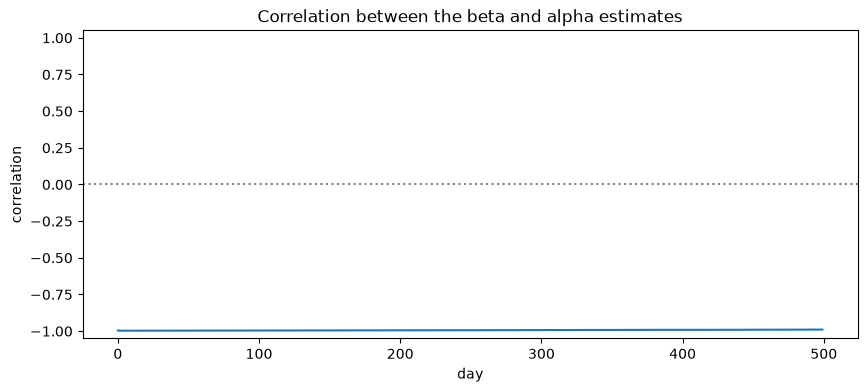

In [8]:
correlation_alpha_beta = state_covariances[:, 0, 1] / np.sqrt(state_covariances[:, 0, 0] * state_covariances[:, 1, 1])

print("correlation of beta and alpha estimates at day 100, 300, 499:",
      np.round(correlation_alpha_beta[[100, 300, 499]], 3))

plt.figure(figsize=(10, 4))
plt.plot(correlation_alpha_beta)
plt.axhline(0, color="gray", linestyle=":")
plt.ylim(-1.05, 1.05)
plt.xlabel("day")
plt.ylabel("correlation")
plt.title("Correlation between the beta and alpha estimates")
plt.show()

The correlation sat near -0.99 for the whole run (-0.996 at day 100 and -0.989 at day 499). The beta and alpha estimates are almost perfectly tied together. The filter is confident about the combination $\alpha + \beta x$, which sets the spread, but much less sure about each part alone. This also explains the wide bands in the earlier plot. It is a limit of the setup, since x varies little around its level, and real prices will likely behave the same way.

## Is the filter calibrated?

If Q and R are reasonable, the innovation divided by its predicted standard deviation, $e_t / \sqrt{S_t}$, should look like noise with standard deviation close to 1. This standardized innovation is exactly the z-score I'll use for trading signals later.

In [9]:
standardized_innovations = innovations_2d / np.sqrt(innovation_variances)

print("std of standardized innovations after day 50:", round(np.std(standardized_innovations[50:]), 3))
print("share beyond +/- 2:", round(np.mean(np.abs(standardized_innovations[50:]) > 2), 3), "(about 0.05 if well calibrated)")

std of standardized innovations after day 50: 1.013
share beyond +/- 2: 0.062 (about 0.05 if well calibrated)


The standardized innovations had a standard deviation of 1.013, and 6.2% fell beyond plus or minus 2 (5% is expected for a calibrated filter). The filter was given the true noise levels, so a result this close to the target is expected. On real data Q and R are guesses, and this check will likely be the first to show a problem.

## Notes

- Leaving out the intercept pushes the missing level into beta, so the hedge ratio is biased (about 3x larger error here). The one-step prediction errors barely change, because a wandering beta can imitate an intercept, so the spread alone would not reveal the problem.
- The state is now a vector and the uncertainty a matrix, but the predict/update structure is exactly the one from notebook 01.
- The off-diagonal of $P$ shows that the individual estimates of alpha and beta are tied together, and the wide uncertainty bands reflect that. What the filter knows well is the combination $\alpha + \beta x$, which is what the spread depends on.

**Next:** run this on a real pair, starting with a cointegration test.